In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import anndata
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]

In [2]:
sb.set_palette('colorblind')

In [3]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [4]:
# figure directory
fig_path = 'figure/'
sc.settings.figdir = fig_path

# Load data

In [5]:
# object from SPI1_CONSTITUTIVE.A01...ipynb - raw count data
query_adata = sc.read('write/SPI1_CONSTITUTIVE_selected_data_raw_count.h5ad')

In [17]:
# transfer celltypist prediction 
hsc = sc.read('write/SPI1_CONSTITUTIVE_selected_HSC.h5ad')
query_adata = query_adata[hsc.obs_names]
query_adata.obs['majority_voting'] = hsc.obs['majority_voting']
query_adata.obs['annot'] = query_adata.obs['majority_voting']

/tmp/ipykernel_404345/2271367121.py:4: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  query_adata.obs['majority_voting'] = hsc.obs['majority_voting']


In [7]:
panfetal = sc.read_h5ad('reference_data_HSC/PAN.A01.v01.raw_count.20210429.HSC_PROGENITORS.embedding.h5ad')

In [8]:
# panfetal - only take HSC_MPP or CYCLING_MPP 
panfetal = panfetal[panfetal.obs['anno_lvl_2_final_clean'].isin(['HSC_MPP','CYCLING_MPP'])]
panfetal.obs['annot'] = panfetal.obs['anno_lvl_2_final_clean'].astype('str')

/tmp/ipykernel_404345/1389190031.py:3: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  panfetal.obs['annot'] = panfetal.obs['anno_lvl_2_final_clean'].astype('str')


In [18]:
# set batch
query_adata.obs['batch'] = 'in_vitro'
panfetal.obs['batch'] = 'in_vivo'

/tmp/ipykernel_404345/2748966395.py:3: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  panfetal.obs['batch'] = 'in_vivo'


## Merge data

In [19]:
gene_common =  list(set(query_adata.var_names) & set(panfetal.var_names))
query_adata = query_adata[:,gene_common]
panfetal = panfetal[:,gene_common]

In [20]:
## Merge
adata = anndata.concat([query_adata, panfetal], axis=0,
                              join="outer", merge="unique", uns_merge="unique")

In [21]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Marker gene plot

In [22]:
adata.obs['batch_annot']=adata.obs['batch'].astype('str') + '-' + adata.obs['annot'].astype('str')

In [24]:
adata.obs['batch_annot'] = adata.obs['batch_annot'].astype('category')

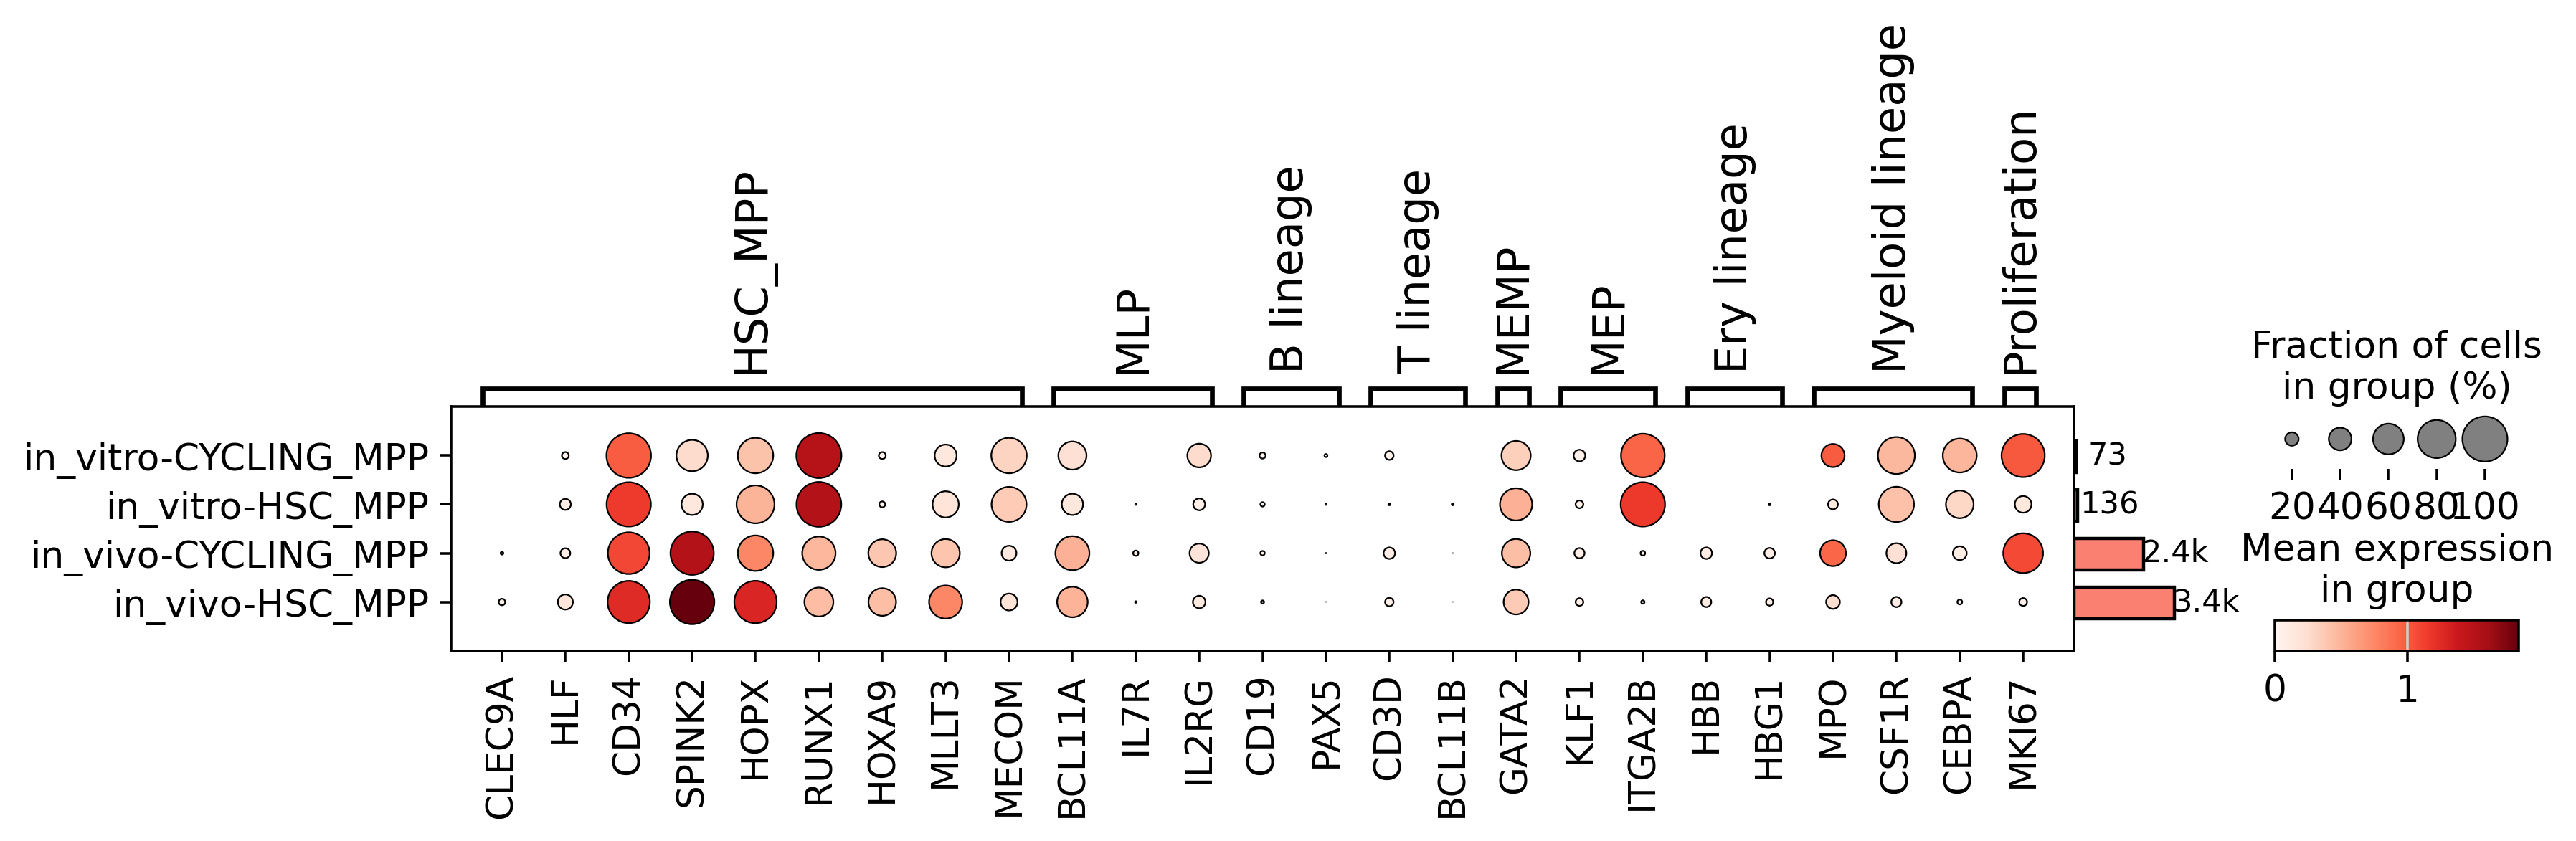

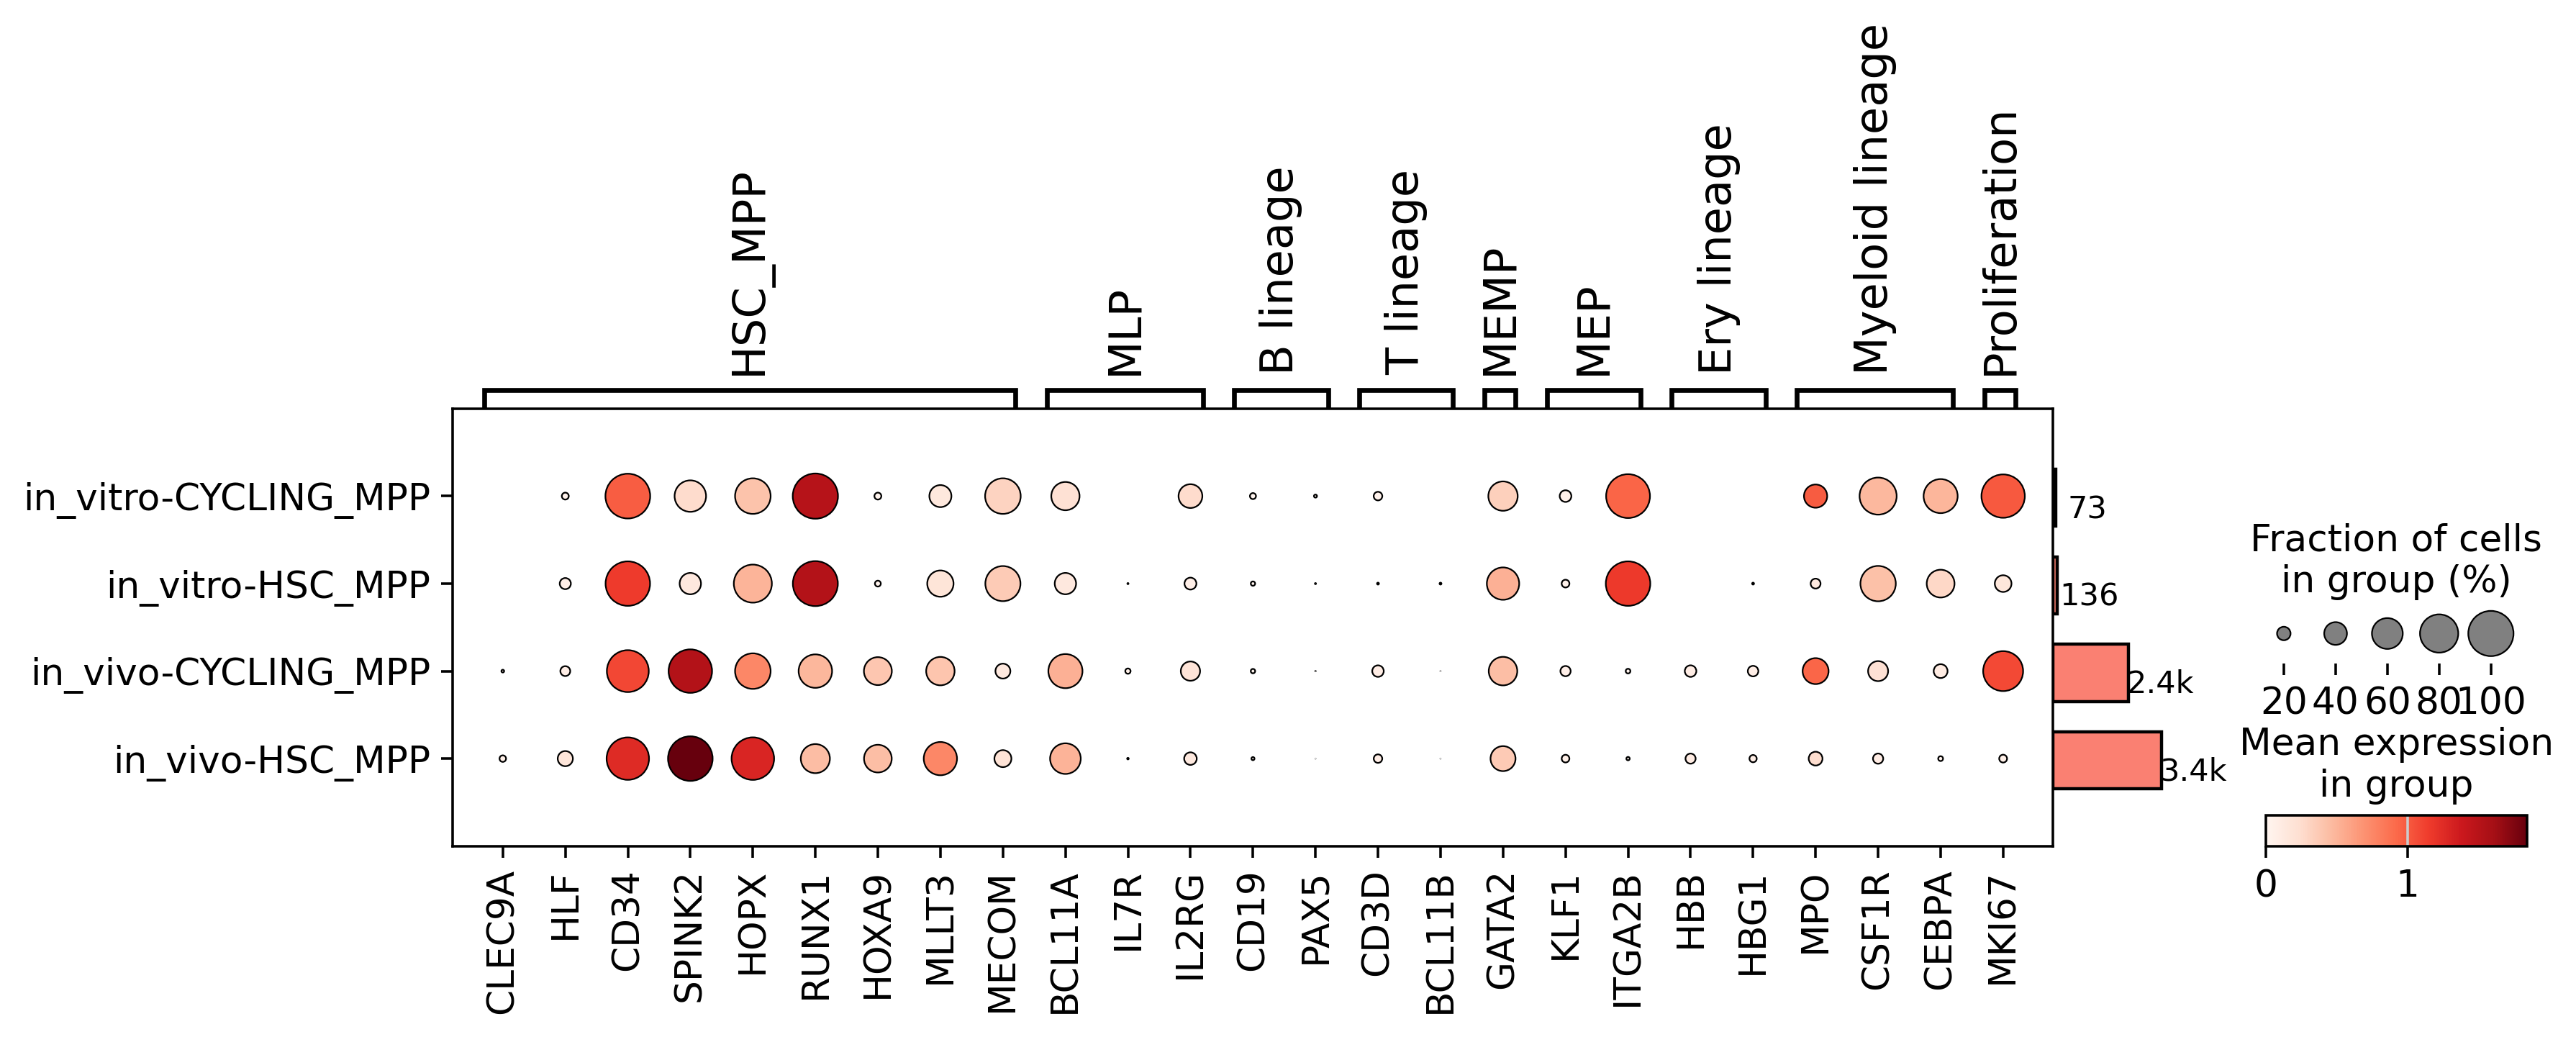

In [30]:
markers = {
    'HSC_MPP':['CLEC9A','HLF','CD34','SPINK2','HOPX','RUNX1','HOXA9','MLLT3','MECOM'],
'MLP':['BCL11A','IL7R','IL2RG'],
'B lineage':['CD19','PAX5'],
'T lineage':['CD3D','BCL11B'],
'MEMP':['GATA2'],
'MEP':['KLF1','ITGA2B'],
'Ery lineage':['HBB','HBG1'],
'Myeloid lineage':['MPO','CSF1R','CEBPA'],
    'Proliferation':['MKI67']
}
#sc.pl.dotplot(concat_adata_hsc, markers, 'annot_combine', dendrogram=False, use_raw=False, save='SPI1_CONSTITUTIVE_dotplot.pdf')

dp = sc.pl.dotplot(adata, markers, 'batch_annot', return_fig=True)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()
#fig = dp.figure
dp.savefig(fig_path+"SPI1_CONSTITUTIVE_dotplot.pdf", bbox_inches="tight")